# Single Stock Analysis Notebook

Author: Jiajing Wang

## 2.1 Parameters

In [1]:
# Parameters
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = "data/data.db"
output_dir = "outputs"  # Folder for the stock metrics CSV.


In [2]:
# Parameters
ticker = "MSFT"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "data/data.db"
output_dir = "outputs"


## 2.2 Data Loading

- Load cleaned data for the specified ticker and date range
- Display summary: "{Ticker} from {start} to {end}: {N} trading days"
- Show the first and last few rows and actual first/last observation dates. Validate the input and report insufficient history clearly; 20 returns require at least 21 prices.

In [3]:
import numpy as np
import sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.collections import LineCollection
from matplotlib.ticker import PercentFormatter

PRICE_COLUMNS = ['open', 'high', 'low', 'close', 'adj_close']

In [4]:
def load_stock(db_path, ticker, start_date, end_date):
    path = Path(db_path).resolve()
    if not path.is_file():
        raise FileNotFoundError(path)
    if pd.Timestamp(start_date) > pd.Timestamp(end_date):
        raise ValueError("Start date must not follow end date")
    # pick one stock; ORDER BY dates
    with sqlite3.connect(f"file:{path}?mode=ro", uri=True) as conn:
        data = pd.read_sql_query(
            "SELECT * FROM ohlc_hw_cleaned WHERE ticker = ? AND ts BETWEEN ? AND ? ORDER BY ts",
            conn, params=(ticker, start_date, end_date))
    if data.empty:
        raise ValueError(f"No data for {ticker} in this date range")
    data["ts"] = pd.to_datetime(data["ts"])
    return data

In [5]:
data = load_stock(db_path, ticker, start_date, end_date)
print(f"{ticker} from {start_date} to {end_date}: {len(data)} trading days")
print(f"Actual coverage: {data.ts.min():%Y-%m-%d} to {data.ts.max():%Y-%m-%d}")
display(data.head())
display(data.tail())

MSFT from 2024-06-01 to 2024-11-30: 97 trading days
Actual coverage: 2024-06-03 to 2024-10-18


,ts,open,high,low,close,adj_close,volume,ticker,ticker_original,raw_price_filled,volume_filled,raw_bounds_repaired,adjustment_factor,adj_close_original,adjusted_price_repaired,adjustment_source,simple_return,extreme_return_flag,extreme_return_review
0,2024-06-03,415.53,416.43,408.92,413.52,412.78,17484675,MSFT,MSFT,0,0,0,0.998210,412.78,0,supplied_ohlc_matched_ticker_date,-0.003878,0,
1,2024-06-04,412.43,416.44,409.68,416.07,415.32,14348917,MSFT,MSFT,0,0,0,0.998197,415.32,0,supplied_ohlc_matched_ticker_date,0.006167,0,
2,2024-06-05,417.81,424.08,416.30,424.01,423.25,16988038,MSFT,MSFT,0,0,0,0.998208,423.25,0,supplied_ohlc_matched_ticker_date,0.019083,0,
3,2024-06-06,424.01,425.31,420.58,424.52,423.76,14861251,MSFT,MSFT,0,0,0,0.998210,423.76,0,supplied_ohlc_matched_ticker_date,0.001203,0,
4,2024-06-07,426.20,426.28,423.00,423.85,423.09,13621650,MSFT,MSFT,0,0,0,0.998207,423.09,0,supplied_ohlc_matched_ticker_date,-0.001578,0,


,ts,open,high,low,close,adj_close,volume,ticker,ticker_original,raw_price_filled,volume_filled,raw_bounds_repaired,adjustment_factor,adj_close_original,adjusted_price_repaired,adjustment_source,simple_return,extreme_return_flag,extreme_return_review
92,2024-10-14,417.77,424.04,417.52,419.14,419.14,16653100,MSFT,MSFT,0,0,0,1.0,419.14,0,supplied_ohlc_matched_ticker_date,0.006774,0,
93,2024-10-15,422.18,422.48,415.26,418.74,418.74,18900201,MSFT,MSFT,0,0,0,1.0,418.74,0,supplied_ohlc_matched_ticker_date,-0.000954,0,
94,2024-10-16,415.17,416.36,410.48,416.12,416.12,15508932,MSFT,MSFT,0,0,0,1.0,416.12,0,supplied_ohlc_matched_ticker_date,-0.006257,0,
95,2024-10-17,422.36,422.50,415.59,416.72,416.72,14820004,MSFT,MSFT,0,0,0,1.0,NaN,1,supplied_ohlc_matched_ticker_date,0.001442,0,
96,2024-10-18,417.14,419.65,416.26,418.16,418.16,15820564,MSFT,MSFT,0,0,0,1.0,418.16,0,supplied_ohlc_matched_ticker_date,0.003456,0,


## 2.3 Calculate Risk Metrics

Use adjusted close for report returns and drawdown. Use daily log returns for volatility, Sharpe and daily-return statistics.

### Daily Returns:

In [6]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns"""
    # Hint: np.log(prices / prices.shift(1))
    return np.log(prices / prices.shift(1))

### Rolling Volatility (20-day window):

In [7]:
def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility"""
    # Hint: returns.rolling(window).std() * np.sqrt(252)
    return returns.rolling(window).std(ddof=1) * np.sqrt(252)

### Drawdown and Maximum Drawdown:

In [8]:
def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak."""
    # Hint:
    # 1. Calculate cumulative max price
    # 2. Drawdown = (price - cum_max) / cum_max
    cum_max = prices.cummax()
    return (prices - cum_max) / cum_max

### Sharpe Ratio:

In [9]:
def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe ratio"""
    # Hint: (mean_return * 252 - rf) / (std_return * sqrt(252))
    returns = returns.dropna()
    std_return = returns.std(ddof=1)
    # Return NaN when there are insufficient returns or zero volatility.
    if len(returns) < 2 or not np.isfinite(std_return) or std_return <= 0:
        return float("nan")
    return (returns.mean() * 252 - risk_free_rate) / (std_return * np.sqrt(252))

Use adjusted close for report returns and drawdown. Use daily log returns for volatility, Sharpe, and daily-return summary statistics; 

In [10]:
data["log_return"] = calculate_returns(data["adj_close"])
data["rolling_volatility"] = calculate_volatility(data["log_return"])
data["drawdown"] = calculate_max_drawdown(data["adj_close"])
sharpe_ratio = calculate_sharpe_ratio(data["log_return"])
display(data[["ts", "adj_close", "log_return", "rolling_volatility", "drawdown"]].tail())
print("Sharpe Ratio:", "N/A" if pd.isna(sharpe_ratio) else f"{sharpe_ratio:.2f}")

,ts,adj_close,log_return,rolling_volatility,drawdown
92,2024-10-14,419.14,0.006751,0.157876,-0.101945
93,2024-10-15,418.74,-0.000955,0.153223,-0.102803
94,2024-10-16,416.12,-0.006277,0.151159,-0.108416
95,2024-10-17,416.72,0.001441,0.132539,-0.107131
96,2024-10-18,418.16,0.003450,0.132650,-0.104045


Sharpe Ratio: 0.07


## 2.4 Visualization

Create the required 2x2 figure: 
- Adjusted price and 50-day MA
- Daily log returns
- 20-day rolling volatility
- Drawdown

### 50d MA Price

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
plt.close(fig)  # Prevent automatic display until all four panels are ready.
axp, axr, axv, axd = axes.flat
mean_vol = data["rolling_volatility"].mean()

# Color each price segment by its rolling volatility; gray means unavailable.
dates = matplotlib.dates.date2num(data["ts"])
points = np.column_stack([dates, data["adj_close"]])
segments = np.stack([points[:-1], points[1:]], axis=1)
vol = data["rolling_volatility"].iloc[1:]
colors = np.where(vol.isna(), "gray", np.where(vol > mean_vol, "red", "green"))
axp.add_collection(LineCollection(segments, colors=colors))
axp.plot(data["ts"], data["adj_close"].rolling(50).mean(), label="50-day MA")
axp.autoscale_view()
axp.set(title=f"{ticker} Price and 50-day MA", ylabel="Adjusted price (USD)")
axp.legend();

### Daily returns

In [12]:
# Green bars indicate gains; red bars indicate losses.
colors = np.where(data["log_return"] >= 0, "green", "red")
axr.bar(data["ts"], data["log_return"], color=colors)
axr.axhline(0, color="gray", linewidth=0.8)
axr.set(title=f"{ticker} Daily Returns", ylabel="Daily log return")
axr.yaxis.set_major_formatter(PercentFormatter(1))

### Rolling volatility

In [13]:
vol = data["rolling_volatility"]
axv.plot(data["ts"], vol)
axv.axhline(mean_vol, color="gray", linestyle="--", label="Mean volatility")
# Shade high volatility red and low volatility green.
axv.fill_between(data["ts"], vol, mean_vol, where=vol > mean_vol, color="red", alpha=0.2)
axv.fill_between(data["ts"], vol, mean_vol, where=vol <= mean_vol, color="green", alpha=0.2)
axv.set(title=f"{ticker} Rolling Volatility (20-day)", ylabel="Annualized volatility")
axv.yaxis.set_major_formatter(PercentFormatter(1))
axv.legend();

### Drawdown and completed figure

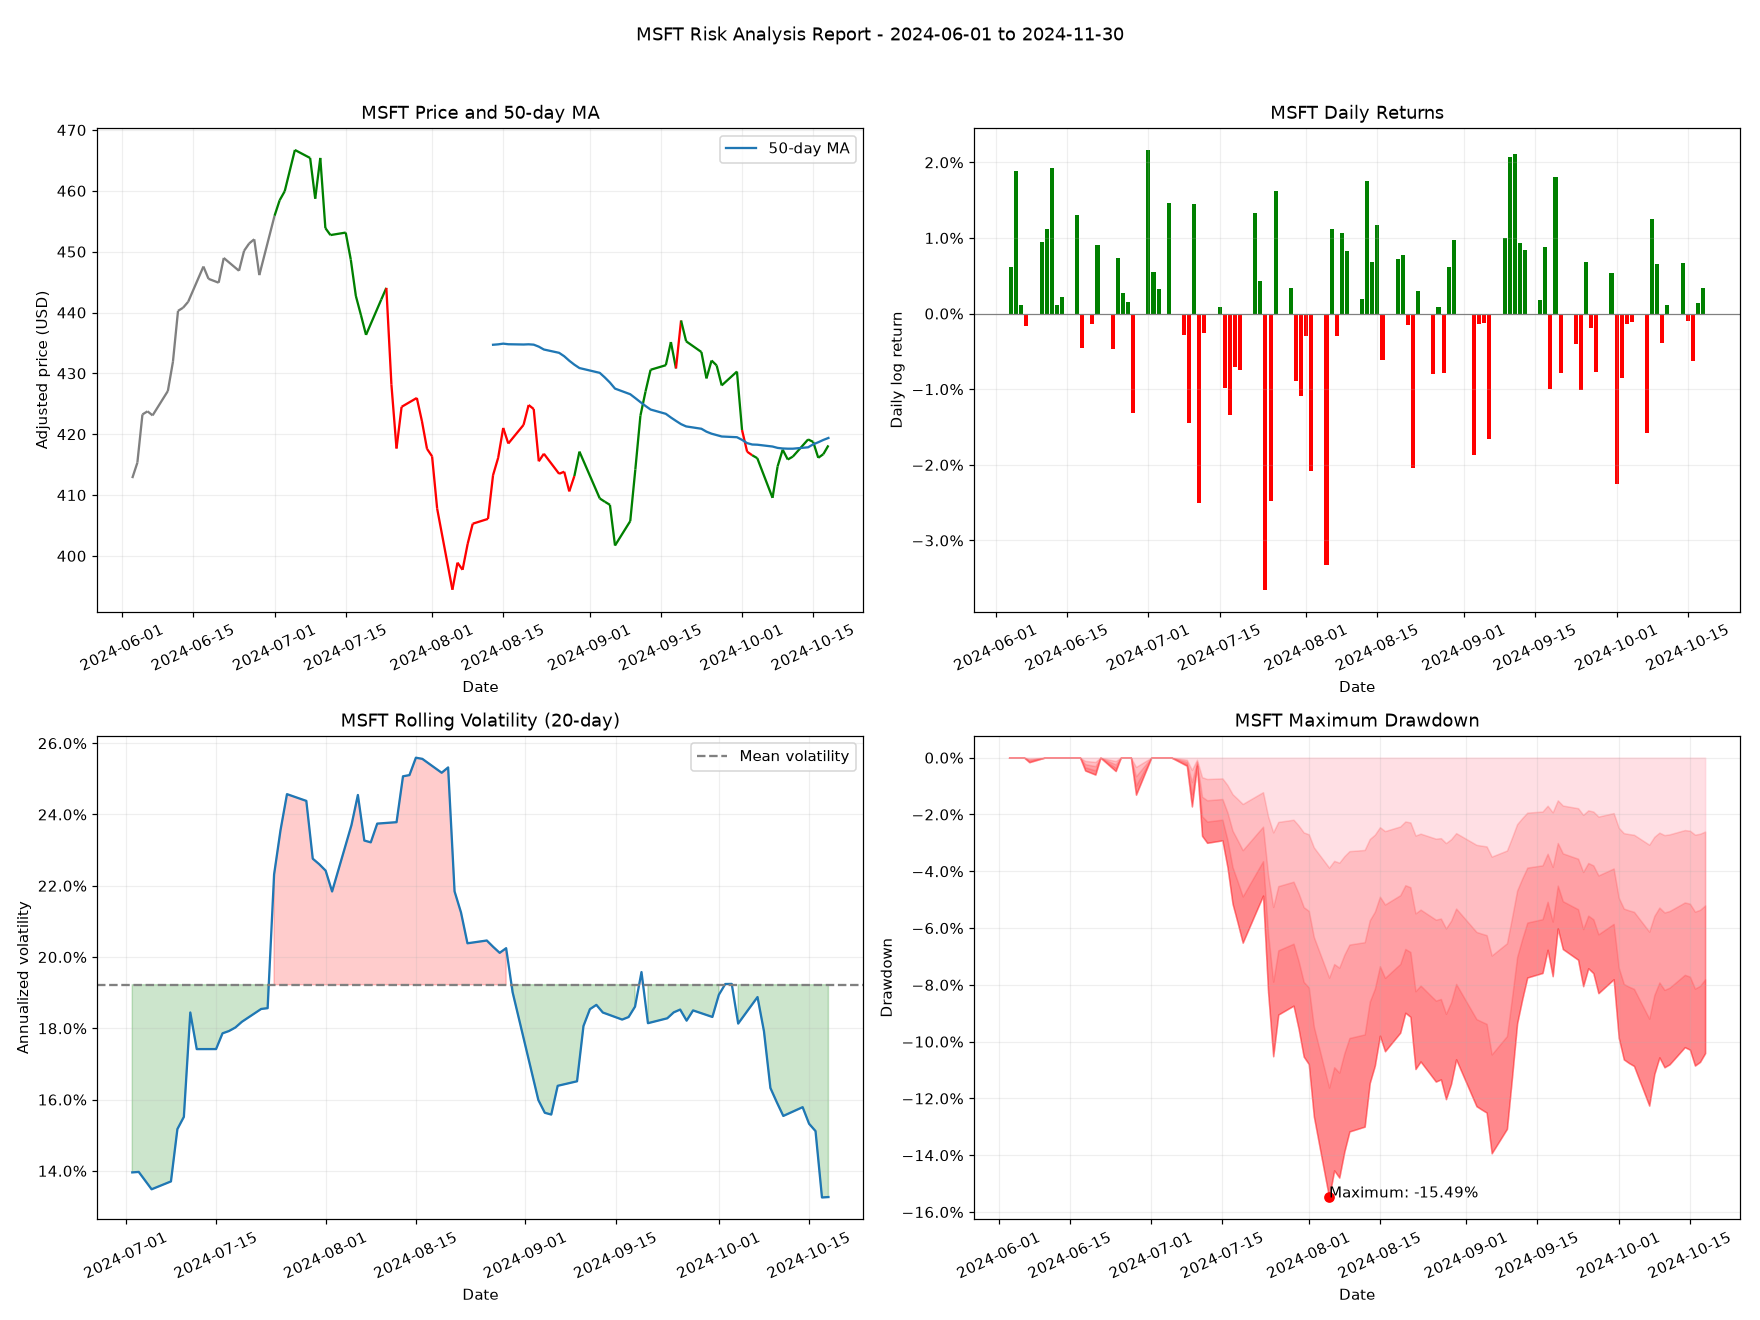

In [14]:
drawdown = data["drawdown"]
axd.fill_between(data["ts"], drawdown, 0, color="pink", alpha=0.5)
for fraction in [0.25, 0.5, 0.75]:
    axd.fill_between(data["ts"], drawdown, drawdown * fraction, color="red", alpha=0.15)
worst = drawdown.idxmin()
axd.scatter(data.loc[worst, "ts"], drawdown.loc[worst], color="red")
axd.annotate(f"Maximum: {drawdown.loc[worst]:.2%}",
             (data.loc[worst, "ts"], drawdown.loc[worst]))
axd.set(title=f"{ticker} Maximum Drawdown", ylabel="Drawdown")
axd.yaxis.set_major_formatter(PercentFormatter(1))

for ax in axes.flat:
    ax.grid(alpha=0.2)
    ax.set_xlabel("Date")
    ax.tick_params(axis="x", rotation=25)
fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}")
fig.tight_layout(rect=[0, 0, 1, 0.96])

# Embed the figure so it is also visible in Papermill's saved notebook.
from io import BytesIO
from IPython.display import Image
buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=110)
display(Image(data=buffer.getvalue()))
plt.close(fig)

## 2.5 Summary Statistics Table

Total return uses last/first adjusted close minus one. Annualized return compounds log returns over 252 sessions. Whole-period volatility differs from mean rolling volatility. Best/worst days and up/down averages use log returns; positive-day share includes zero returns in the denominator. Empty conditional subsets and undefined Sharpe display N/A.

In [15]:
def summary_metrics(data):
    """Compute all ten required metrics as fractions, except the dimensionless Sharpe."""
    returns = data.log_return.dropna()
    up, down = returns[returns > 0], returns[returns < 0]
    # Keep fractions here; percentage formatting happens only in the table.
    return {'total_return': float(data.adj_close.iloc[-1] / data.adj_close.iloc[0] - 1),
            'annualized_return': float(np.expm1(returns.mean() * 252)),
            'annualized_volatility': float(returns.std(ddof=1) * np.sqrt(252)),
            'sharpe_ratio': calculate_sharpe_ratio(returns),
            'max_drawdown': float(data.drawdown.min()),
            'best_day': float(returns.max()), 'worst_day': float(returns.min()),
            'positive_days': float((returns > 0).mean()),
            'average_up_day': float(up.mean()), 'average_down_day': float(down.mean())}

In [16]:
metrics = summary_metrics(data)
labels = {
    "total_return": "Total Return", "annualized_return": "Annualized Return",
    "annualized_volatility": "Annualized Volatility", "sharpe_ratio": "Sharpe Ratio",
    "max_drawdown": "Maximum Drawdown", "best_day": "Best Day",
    "worst_day": "Worst Day", "positive_days": "Positive Days",
    "average_up_day": "Average Up Day", "average_down_day": "Average Down Day",
}
summary_table = pd.DataFrame([
    {"Metric": labels[key], "Value": "N/A" if pd.isna(value) else
     f"{value:.2f}" if key == "sharpe_ratio" else f"{value:+.2%}"}
    for key, value in metrics.items()
])
display(summary_table)

,Metric,Value
0,Total Return,+1.30%
1,Annualized Return,+3.46%
2,Annualized Volatility,+18.74%
3,Sharpe Ratio,0.07
4,Maximum Drawdown,-15.49%
5,Best Day,+2.16%
6,Worst Day,-3.65%
7,Positive Days,+54.17%
8,Average Up Day,+0.86%
9,Average Down Day,-0.98%


## Named Outputs for Part 3

- 02_stock_report_template.ipynb with parameters cell tagged
- All functions documented with docstrings
- Beautiful visualizations

In [17]:
# Save one row; keep returns as fractions (0.12 means 12%).
report_metrics = pd.DataFrame([{
    "ticker": ticker,
    "avg_daily_return": data["log_return"].mean(),
    "avg_volatility": data["rolling_volatility"].mean(),
    "max_drawdown": metrics["max_drawdown"],
    "sharpe_ratio": metrics["sharpe_ratio"],
    "total_return": metrics["total_return"],
    "actual_start": data["ts"].min().strftime("%Y-%m-%d"),
    "actual_end": data["ts"].max().strftime("%Y-%m-%d"),
    "n_prices": len(data),
}])

# Create the output folder and save this stock's results.
output = Path(output_dir)
output.mkdir(parents=True, exist_ok=True)
report_metrics.to_csv(output / f"{ticker}_metrics.csv", index=False)
display(report_metrics)


,ticker,avg_daily_return,avg_volatility,max_drawdown,sharpe_ratio,total_return,actual_start,actual_end,n_prices
0,MSFT,0.000135,0.192236,-0.154868,0.074679,0.013034,2024-06-03,2024-10-18,97
